In [1]:
import time
import copy

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Available GPUs:", torch.cuda.device_count())

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

Device: cuda
Available GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


In [3]:
SEED = 42
BATCH_SIZE = 16
IMAGE_SIZE = 224

CLASS_NAMES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

torch.manual_seed(SEED)
np.random.seed(SEED)

In [4]:
# Нормалізація для попередньо навченої ViT
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

In [5]:
full_train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)

full_val_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=eval_transform
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=eval_transform
)

train_indices, val_indices = train_test_split(
    np.arange(len(full_train_dataset)),
    test_size=0.1,
    stratify=full_train_dataset.targets,
    random_state=SEED
)

train_dataset = Subset(full_train_dataset, train_indices)
val_dataset = Subset(full_val_dataset, val_indices)

100%|██████████| 170M/170M [18:47<00:00, 151kB/s]  


In [6]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

In [7]:
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

images, labels = next(iter(train_loader))

print("\nImages shape:", images.shape)
print("Labels shape:", labels.shape)

Train: 45000
Validation: 5000
Test: 10000

Images shape: torch.Size([16, 3, 224, 224])
Labels shape: torch.Size([16])


In [8]:
weights = models.ViT_B_16_Weights.IMAGENET1K_V1

model = models.vit_b_16(weights=weights)

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 177MB/s] 


In [9]:
print(model.heads)

Sequential(
  (head): Linear(in_features=768, out_features=1000, bias=True)
)


In [10]:
model.heads.head = nn.Linear(
    in_features=768,
    out_features=10
)

print(model.heads)

Sequential(
  (head): Linear(in_features=768, out_features=10, bias=True)
)


In [11]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters: 85,806,346
Trainable parameters: 85,806,346


In [12]:
criterion = nn.CrossEntropyLoss()

In [13]:
backbone_params = [
    param for name, param in model.named_parameters()
    if not name.startswith("heads.")
]

head_params = list(model.heads.parameters())

optimizer = optim.AdamW(
    [
        {"params": backbone_params, "lr": 1e-4},
        {"params": head_params, "lr": 1e-3}
    ],
    weight_decay=0.05
)

In [14]:
print("Loss:", criterion)

for i, group in enumerate(optimizer.param_groups):
    print(f"Group {i + 1}: lr={group['lr']}")

Loss: CrossEntropyLoss()
Group 1: lr=0.0001
Group 2: lr=0.001


In [15]:
def train_one_epoch(model, loader, criterion, optimizer, scaler, device):
    model.train()

    total_loss = 0.0
    correct = 0
    total =0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        with torch.autocast(
            device_type="cuda",
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    avg_loss = total_loss / total
    accuracy = correct / total

    return avg_loss, accuracy

In [16]:
def validate_one_epoch(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                enabled=(device.type == "cuda")
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    avg_loss = total_loss / total
    accuracy = correct / total

    return avg_loss, accuracy

In [17]:
def train_model(model, train_loader, val_loader,
                criterion, optimizer, scaler, device, num_epochs=5):

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    best_val_accuracy = 0.0
    best_epoch = 0

    start_time = time.perf_counter()

    for epoch in range(num_epochs):

        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device
        )

        val_loss, val_acc = validate_one_epoch(
            model, val_loader, criterion, device
        )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)

        print(
            f"Epoch [{epoch + 1}/{num_epochs}] | "
            f"Train Loss: {train_loss:.4f}, "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f}, "
            f"Val Acc: {val_acc:.4f}",
            flush=True
        )

        # Зберігаємо найкращу модель
        if val_acc > best_val_accuracy:
            best_val_accuracy = val_acc
            best_epoch = epoch + 1

            torch.save(
                model.state_dict(),
                "/kaggle/working/vit_best.pth"
            )

        # Зберігаємо стан навчання після кожної епохи
        checkpoint = {
            "epoch": epoch + 1,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scaler_state": scaler.state_dict(),
            "history": history,
            "best_val_accuracy": best_val_accuracy,
            "best_epoch": best_epoch
        }

        torch.save(
            checkpoint,
            "/kaggle/working/vit_checkpoint.pth"
        )

    training_time = time.perf_counter() - start_time

    print(f"\nTraining time: {training_time:.1f} seconds")
    print(f"Best epoch: {best_epoch}")
    print(f"Best Validation Accuracy: {best_val_accuracy:.4f}")

    return history

In [18]:
model = model.to(device)

print(model.heads)

Sequential(
  (head): Linear(in_features=768, out_features=10, bias=True)
)


In [19]:
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

In [20]:
model.eval()

images, labels = next(iter(val_loader))
images = images.to(device)

with torch.inference_mode():
    with torch.autocast(
        device_type="cuda",
        enabled=(device.type == "cuda")
    ):
        outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([16, 3, 224, 224])
Output shape: torch.Size([16, 10])


In [21]:
model.train()

images, labels = next(iter(train_loader))
images = images.to(device, non_blocking=True)
labels = labels.to(device, non_blocking=True)

optimizer.zero_grad()

with torch.autocast(
    device_type="cuda",
    enabled=(device.type == "cuda")
):
    outputs = model(images)
    loss = criterion(outputs, labels)

scaler.scale(loss).backward()
scaler.step(optimizer)
scaler.update()

print(f"Training Loss: {loss.item():.4f}")
print("Output shape:", outputs.shape)

Training Loss: 2.2766
Output shape: torch.Size([16, 10])


In [22]:
weights = models.ViT_B_16_Weights.IMAGENET1K_V1

model = models.vit_b_16(weights=weights)

model.heads.head = nn.Linear(
    in_features=768,
    out_features=10
)

model = model.to(device)

In [23]:
backbone_params = [
    param for name, param in model.named_parameters()
    if not name.startswith("heads.")
]

head_params = list(model.heads.parameters())

optimizer = optim.AdamW(
    [
        {"params": backbone_params, "lr": 1e-4},
        {"params": head_params, "lr": 1e-3}
    ],
    weight_decay=0.05
)

scaler = torch.amp.GradScaler("cuda")

In [24]:
print("GPU:", torch.cuda.get_device_name(0))

total_memory = torch.cuda.get_device_properties(0).total_memory
allocated_memory = torch.cuda.memory_allocated(0)

print(f"Total GPU memory: {total_memory / 1024**3:.2f} GB")
print(f"Allocated GPU memory: {allocated_memory / 1024**3:.2f} GB")

GPU: Tesla T4
Total GPU memory: 14.56 GB
Allocated GPU memory: 1.00 GB


In [25]:
NUM_EPOCHS = 5

history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    num_epochs=NUM_EPOCHS
)

Epoch [1/5] | Train Loss: 0.3372, Train Acc: 0.8875 | Val Loss: 0.2219, Val Acc: 0.9288
Epoch [2/5] | Train Loss: 0.2311, Train Acc: 0.9221 | Val Loss: 0.1910, Val Acc: 0.9356
Epoch [3/5] | Train Loss: 0.1946, Train Acc: 0.9343 | Val Loss: 0.2456, Val Acc: 0.9186
Epoch [4/5] | Train Loss: 0.1688, Train Acc: 0.9427 | Val Loss: 0.1966, Val Acc: 0.9336
Epoch [5/5] | Train Loss: 0.1490, Train Acc: 0.9498 | Val Loss: 0.1729, Val Acc: 0.9394

Training time: 2841.4 seconds
Best epoch: 5
Best Validation Accuracy: 0.9394


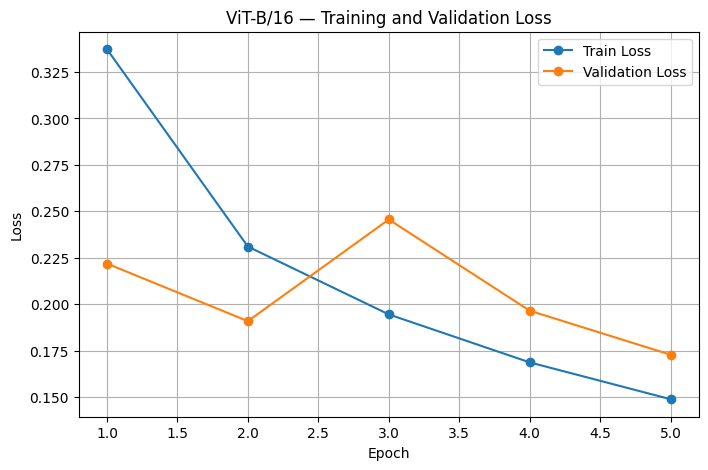

In [26]:
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ViT-B/16 — Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

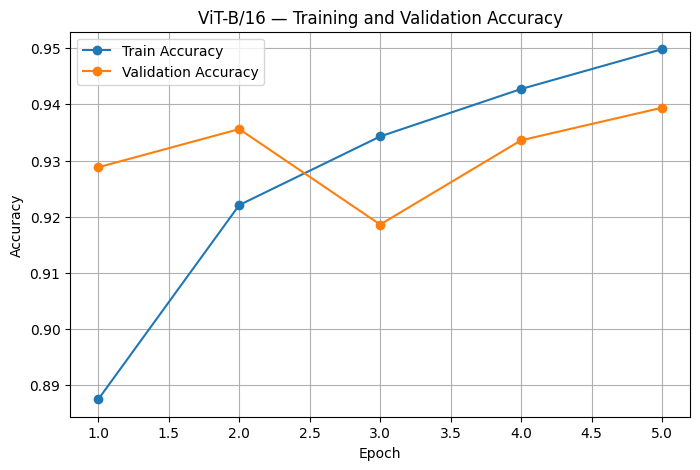

In [27]:
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_accuracy"], marker="o", label="Train Accuracy")
plt.plot(epochs, history["val_accuracy"], marker="o", label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ViT-B/16 — Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [28]:
model.load_state_dict(
    torch.load(
        "/kaggle/working/vit_best.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Best model loaded successfully!")

Best model loaded successfully!


In [29]:
all_true_labels = []
all_predicted_labels = []

model.eval()

with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)

        predicted_classes = outputs.argmax(dim=1)

        all_true_labels.extend(labels.cpu().tolist())
        all_predicted_labels.extend(predicted_classes.cpu().tolist())

In [30]:
test_accuracy = accuracy_score(
    all_true_labels, all_predicted_labels
)

test_precision = precision_score(
    all_true_labels, all_predicted_labels,
    average="macro", zero_division=0
)

test_recall = recall_score(
    all_true_labels, all_predicted_labels,
    average="macro", zero_division=0
)

test_f1 = f1_score(
    all_true_labels, all_predicted_labels,
    average="macro", zero_division=0
)

print("\n=== Test Results ===")
print(f"Test Accuracy:  {test_accuracy:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall:    {test_recall:.4f}")
print(f"Test F1-score:  {test_f1:.4f}")


=== Test Results ===
Test Accuracy:  0.9362
Test Precision: 0.9381
Test Recall:    0.9362
Test F1-score:  0.9362


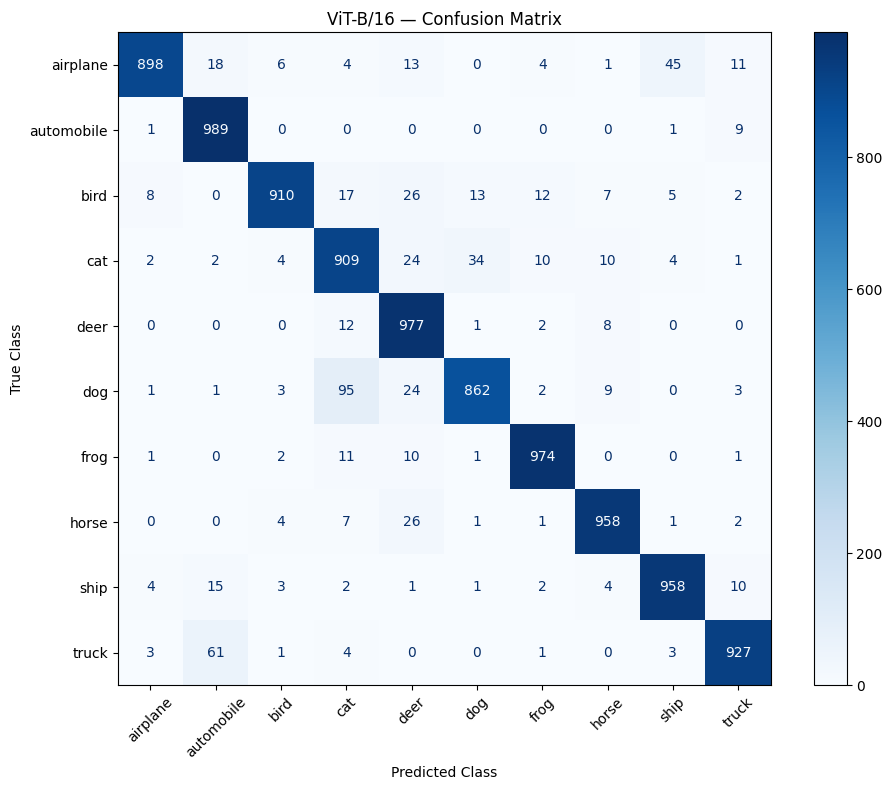

In [31]:
cm = confusion_matrix(all_true_labels, all_predicted_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("True Class")
ax.set_title("ViT-B/16 — Confusion Matrix")

plt.tight_layout()
plt.show()

In [32]:
print(classification_report(
    all_true_labels,
    all_predicted_labels,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

    airplane     0.9782    0.8980    0.9364      1000
  automobile     0.9107    0.9890    0.9482      1000
        bird     0.9753    0.9100    0.9415      1000
         cat     0.8567    0.9090    0.8821      1000
        deer     0.8874    0.9770    0.9300      1000
         dog     0.9441    0.8620    0.9012      1000
        frog     0.9663    0.9740    0.9701      1000
       horse     0.9609    0.9580    0.9594      1000
        ship     0.9420    0.9580    0.9499      1000
       truck     0.9596    0.9270    0.9430      1000

    accuracy                         0.9362     10000
   macro avg     0.9381    0.9362    0.9362     10000
weighted avg     0.9381    0.9362    0.9362     10000

